# Experiments: second iteration

Milestone 5 of *Evaluating lineage link prediction with Valentine*.

The first iteration (`04_experiments.ipynb`) found that Valentine's value-based matchers rank lineage links far above
random (held-out PR-AUC 0.21 vs 0.06), but it listed four weaknesses and next steps. This notebook tests each of
them:

| question (from the first iteration) | what we try | code | section |
|---|---|---|---|
| Do table names make the task easier than in a real database? | match with `raw`, `base` and `neutral` table names | `src/matching.py` | 1 |
| `mean` misses join sources that gave one column, `max` is fooled by keys | hybrid `w * mean + (1 - w) * max` | `src/combination.py` | 2 |
| Names and values carry different evidence | average of matchers; logistic regression on all scores (stacking) | `src/combination.py` | 3 |
| The score does not give the direction of a link | second signal: object type, score asymmetry, row counts | `src/combination.py` | 4 |
| How do results depend on the kind of lineage? | results per scenario type (join, fewer rows, same rows, bridged) | `src/scenarios.py` | 5 |

**Protocol (unchanged).** Everything that is chosen or fitted (weights, regularisation, thresholds) uses the
`train` split only; `test` + `multi` (19 of the 30 links) are reported as held-out.

The notebook needs the cached column scores of `src/matching.py` for the three name variants (about 2 minutes each
on the first run):

```
cd src
python matching.py --names raw
python matching.py --names neutral
python matching.py --names base
```

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path("..", "src").resolve()))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from combination import (CATALOG_ORDER, HELD_OUT, TYPE_ORDER, apply_direction, choose_C, combine_matchers,
                         config, direction_accuracy, direction_signals, fit_weight, hybrid_aggregation,
                         stacking, wide_scores)
from evaluation import (best_threshold, evaluate_all, hits_vs_sampled_negatives, ranking_metrics, table_scores,
                        threshold_metrics)
from lineage_data import load_all
from matching import MATCHERS, RESULTS_DIR, column_scores
from preprocessing import load_processed, preprocess_all
from scenarios import link_scenarios

pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 200)
FIGURES = Path("..", "docs", "figures")
FIGURES.mkdir(parents=True, exist_ok=True)

# Same chart style as the earlier notebooks.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GREY, LIGHT_GREY, MUTED, GRID, SURFACE = "#898781", "#c3c2b7", "#52514e", "#e1e0d9", "#ffffff"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 8,
    "axes.edgecolor": LIGHT_GREY, "axes.labelcolor": MUTED, "axes.titlesize": 8.5,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})

METRICS = ["PR-AUC", "AUROC", "Hits@1", "Hits@3", "MRR"]


def held(scored):
    """Ranking metrics on the held-out splits."""
    return ranking_metrics(scored[scored.split.isin(HELD_OUT)])


def train_metrics(scored):
    return ranking_metrics(scored[scored.split == "train"])


data, pairs, tables = load_processed()
splits, _ = preprocess_all(load_all())          # Split objects (lineage log, object kinds)
scored = {names: table_scores(column_scores(names, progress=False)[0], pairs, data)
          for names in ["raw", "neutral", "base"]}
first = config(scored["raw"], "Jaccard distance", "mean")     # best configuration of the first iteration
print("first iteration, held-out:", {k: round(v, 3) for k, v in held(first).items()})

first iteration, held-out: {'PR-AUC': 0.206, 'AUROC': 0.86, 'Hits@1': np.float64(0.4), 'Hits@3': np.float64(0.733), 'Hits@10': np.float64(1.0), 'MRR': np.float64(0.589)}


## 1. Table names on/off

Object names in the benchmark carry the scenario step (`vw`, `Table`, `temp`, `Final`) and often the name of their
source. If Valentine used them, the results would be easier than in a real database. We matched all pairs three
times: with the `raw` names, the `base` names without type prefix and `neutral` names (`aaa`, `bbb`, which share no
characters), and compare the best aggregation (`mean`) of every matcher.

In [2]:
by_names = {}
for names, part in scored.items():
    ranking = evaluate_all(part[part.aggregation == "mean"])
    by_names[names] = ranking[ranking["evaluated on"] == "held-out (test+multi)"].set_index("matcher")[["PR-AUC", "MRR"]]
names_table = pd.concat(by_names, axis=1).reindex(list(MATCHERS))
names_table.round(3)

raw        neutral          base       
                          PR-AUC    MRR  PR-AUC    MRR PR-AUC    MRR
matcher                                                             
COMA (schema)              0.175  0.448   0.175  0.448  0.175  0.448
COMA (schema + instances)  0.201  0.552   0.201  0.552  0.201  0.552
Cupid                      0.173  0.483   0.173  0.483  0.173  0.483
Similarity Flooding        0.068  0.340   0.074  0.330  0.066  0.326
Jaccard distance           0.206  0.589   0.206  0.589  0.206  0.589
Distribution-based         0.186  0.519   0.183  0.496  0.185  0.507

In [3]:
keys = ["split", "source", "target", "matcher", "aggregation"]
differ = {}
for names in ["neutral", "base"]:
    both = scored["raw"].merge(scored[names], on=keys, suffixes=("_raw", "_other"))
    differ[names] = (both.score_raw - both.score_other).abs().gt(1e-9).groupby(both.matcher).sum()
differ = pd.DataFrame(differ).reindex(list(MATCHERS)).astype(int)
differ.columns = [f"pair scores that differ from raw: {c}" for c in differ.columns]
differ

,pair scores that differ from raw: neutral,pair scores that differ from raw: base
matcher,,
COMA (schema),0,0
COMA (schema + instances),0,0
Cupid,0,0
Similarity Flooding,1688,1023
Jaccard distance,0,0
Distribution-based,548,301


**Valentine's column scores do not depend on the table names** for COMA, Cupid and Jaccard: every score is the same
with raw, base and neutral names. Only Similarity Flooding (which puts the table name into its graph) and
Distribution-based (whose clustering uses the table name as a tie-breaker) change slightly, and their PR-AUC moves by
less than 0.01. The results of the first iteration are therefore **not inflated by the naming convention** of the
benchmark. Table names only enter our pipeline later, through the direction signal of section 4, where we discuss
this openly. All following sections use the `raw` scores.

## 2. Combining aggregations: `mean` and `max`

`mean` rewards a target that takes most of its columns from the source, `max` a single perfectly matched column (a
join source that gave one column). We mix them, `score = w * mean + (1 - w) * max`, and choose `w` on train.

In [4]:
hybrid_rows, curves = [], {}
for matcher in ["Jaccard distance", "COMA (schema + instances)", "Distribution-based", "COMA (schema)"]:
    w, curve = fit_weight(scored["raw"], matcher)
    curves[matcher] = curve
    hybrid = hybrid_aggregation(scored["raw"], matcher, w)
    hybrid_rows.append({"matcher": matcher, "w chosen on train": w,
                        "held-out PR-AUC, mean": held(config(scored["raw"], matcher, "mean"))["PR-AUC"],
                        "held-out PR-AUC, hybrid": held(hybrid)["PR-AUC"],
                        "held-out MRR, mean": held(config(scored["raw"], matcher, "mean"))["MRR"],
                        "held-out MRR, hybrid": held(hybrid)["MRR"]})
pd.DataFrame(hybrid_rows).set_index("matcher").round(3).T

matcher,Jaccard distance,COMA (schema + instances),Distribution-based,COMA (schema)
w chosen on train,0.200,1.000,0.100,1.000
"held-out PR-AUC, mean",0.206,0.201,0.186,0.175
"held-out PR-AUC, hybrid",0.199,0.201,0.193,0.175
"held-out MRR, mean",0.589,0.552,0.519,0.448
"held-out MRR, hybrid",0.600,0.552,0.508,0.448


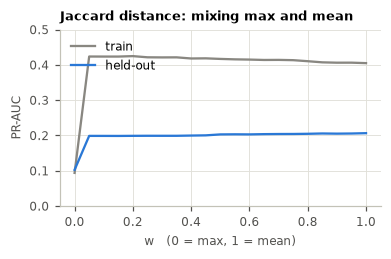

In [5]:
fig, ax = plt.subplots(figsize=(3.6, 2.4))
curve = curves["Jaccard distance"]
ax.plot(curve.weight, curve.train, color=GREY, linewidth=1.5, label="train")
ax.plot(curve.weight, curve["held-out"], color=BLUE, linewidth=1.5, label="held-out")
ax.set_xlabel("w   (0 = max, 1 = mean)")
ax.set_ylabel("PR-AUC")
ax.set_ylim(0, 0.5)
ax.legend(loc="upper left")
ax.set_title("Jaccard distance: mixing max and mean")
fig.tight_layout()
fig.savefig(FIGURES / "it2_01_hybrid_weight.png")
plt.show()

Mixing in `max` does **not** help. Pure `max` (`w = 0`) is poor; as soon as some `mean` is added the PR-AUC jumps to
the level of `mean` and stays flat, on train and held-out alike. The weight chosen on train (0.2 for Jaccard) gives
the same held-out PR-AUC as `mean` (0.20 vs 0.21). Moving the single-column join sources up with `max` also moves up
every pair that shares a key, so the gain and the loss cancel. The join sources need other evidence (section 5).

## 3. Combining matchers

Values and names fail in different places, so we combine matchers in two ways:

* **average**: the unweighted mean of several `matcher | aggregation` scores (no fitting);
* **stacking**: a logistic regression on all 24 `matcher | aggregation` scores, fitted on train only. Train has 11
  positive pairs, so the model is strongly regularised and class-balanced; its regularisation `C` is chosen by
  cross-validation over the derived tables of train.

In [6]:
wide = wide_scores(scored["raw"])
all_columns = [c for c in wide.columns if " | " in c]
averages = {
    "Jaccard + COMA (schema)": ["Jaccard distance | mean", "COMA (schema) | mean"],
    "Jaccard + COMA (schema + instances)": ["Jaccard distance | mean", "COMA (schema + instances) | mean"],
    "all six matchers (mean)": [c for c in all_columns if c.endswith("| mean")],
}
C, cv = choose_C(wide, all_columns)
print(f"C chosen by cross-validation on train: {C}")
cv.round(3)

C chosen by cross-validation on train: 0.1


,C,CV PR-AUC (train)
0,0.01,0.498
1,0.10,0.503
2,1.00,0.455
3,10.00,0.452


In [7]:
systems = {"first iteration: Jaccard distance + mean": first}
for name, columns in averages.items():
    systems[f"average: {name}"] = combine_matchers(wide, columns)
stacked, coefficients = stacking(wide, all_columns, C=C)
systems["stacking: logistic regression on 24 scores"] = stacked

combination_table = pd.DataFrame({name: {"train PR-AUC": train_metrics(s)["PR-AUC"], **held(s)}
                                  for name, s in systems.items()}).T
combination_table[["train PR-AUC"] + METRICS].round(3)

,train PR-AUC,PR-AUC,AUROC,Hits@1,Hits@3,MRR
first iteration: Jaccard distance + mean,0.405,0.206,0.860,0.400,0.733,0.589
average: Jaccard + COMA (schema),0.388,0.207,0.842,0.333,0.667,0.561
average: Jaccard + COMA (schema + instances),0.421,0.210,0.859,0.400,0.733,0.611
average: all six matchers (mean),0.379,0.215,0.845,0.400,0.867,0.644
stacking: logistic regression on 24 scores,0.425,0.255,0.860,0.400,0.933,0.651


In [8]:
coefficients.round(2).to_frame("weight").T

,Cupid | coverage,Jaccard distance | max,Cupid | max,Cupid | mean,Jaccard distance | coverage,Distribution-based | max,Jaccard distance | mean,Distribution-based | mean,Jaccard distance | top3,Distribution-based | coverage,...,Similarity Flooding | mean,Similarity Flooding | max,COMA (schema) | mean,COMA (schema + instances) | top3,Similarity Flooding | top3,COMA (schema) | coverage,COMA (schema + instances) | max,COMA (schema) | max,COMA (schema) | top3,Similarity Flooding | coverage
weight,0.76,0.72,0.62,0.61,0.53,0.51,0.44,0.41,0.38,0.37,...,0.11,0.07,0.06,0.06,0.06,0.02,-0.16,-0.24,-0.32,-0.4


* Averaging two or six matchers changes the held-out results very little (PR-AUC 0.21 to 0.22). The matchers agree
  on the easy links and fail together on the hard ones.
* **Stacking** improves the ranking: held-out PR-AUC 0.21 -> 0.25, Hits@3 0.73 -> 0.93, MRR 0.59 -> 0.65. The largest
  weights go to Cupid and to the instance-based scores (`Jaccard | max`, `Jaccard | coverage`, `Distribution-based`),
  while COMA's schema `max` / `top3` and Similarity Flooding get negative weights: the model learns that a single
  similar column *name* is weak evidence. With 11 training positives this is a small model on a small sample, so we
  treat the gain as indicative, not as a final number.

## 4. Direction of a link

The score of `A -> B` measures how much of `B` is found in `A`; for copies it is the same in both directions, and a
derived table with extra columns can even score higher backwards. We test three independent direction votes for every
pair (`src/combination.py`):

| signal | idea | available in a real database? |
|---|---|---|
| `score` | score(A -> B) > score(B -> A) | yes |
| `rows` | the larger table comes first (selection, aggregation, join on a key) | yes |
| `type` | object type order: original base table < view < table < temporary table < final table | partly: base table / view / temporary table are in the catalog; the order of later steps comes from the benchmark's naming convention |
| `catalog` | weaker `type`: only "original base table before anything created later" | yes |

In [9]:
votes = direction_signals(pairs, first, splits)
votes_catalog = direction_signals(pairs, first, splits, CATALOG_ORDER)
orders = {
    "score only (first iteration)": (votes, ("vote_score",)),
    "rows only": (votes, ("vote_rows",)),
    "catalog only": (votes_catalog, ("vote_type",)),
    "catalog, then score, then rows": (votes_catalog, ("vote_type", "vote_score", "vote_rows")),
    "type only": (votes, ("vote_type",)),
    "type, then score, then rows": (votes, ("vote_type", "vote_score", "vote_rows")),
}
direction_table = pd.DataFrame({name: direction_accuracy(v, order) for name, (v, order) in orders.items()}).T
direction_table["share correct"] = (direction_table.correct / 30).round(2)
direction_table

,correct,undecided,wrong,share correct
score only (first iteration),18,6,6,0.60
rows only,9,14,7,0.30
catalog only,14,16,0,0.47
"catalog, then score, then rows",22,5,3,0.73
type only,29,1,0,0.97
"type, then score, then rows",29,1,0,0.97


The score alone gets 18 of 30 directions right, the row count only 9 (join views have more rows than their small
lookup sources). The object type order decides 29 of 30 correctly and abstains on one pair of two derived tables
(`OrderDetailsDummy -> OrderSummary`). The catalog-only prior never errs but only decides the 14 links that start
in an original table; falling back to the score for the rest makes 3 errors.

We use the decided direction to **demote reverse pairs**: a pair whose decided direction is the reverse gets score
0, so it moves to the bottom of the ranking.

In [10]:
direction_rows = {}
for base_name, base in [("first iteration", first), ("stacking", stacked)]:
    v_type = direction_signals(pairs, base, splits)
    v_cat = direction_signals(pairs, base, splits, CATALOG_ORDER)
    direction_rows[base_name] = held(base)
    direction_rows[f"{base_name} + catalog direction"] = held(apply_direction(base, v_cat, ("vote_type",)))
    direction_rows[f"{base_name} + type direction"] = held(apply_direction(base, v_type, ("vote_type", "vote_score")))
pd.DataFrame(direction_rows).T[METRICS].round(3)

,PR-AUC,AUROC,Hits@1,Hits@3,MRR
first iteration,0.206,0.860,0.400,0.733,0.589
first iteration + catalog direction,0.212,0.874,0.400,0.733,0.589
first iteration + type direction,0.335,0.926,0.533,0.933,0.728
stacking,0.255,0.860,0.400,0.933,0.651
stacking + catalog direction,0.257,0.874,0.400,0.933,0.651
stacking + type direction,0.358,0.924,0.600,0.933,0.762


* With the **object type order**, held-out PR-AUC rises from 0.21 to 0.34 (first iteration) and from 0.25 to 0.36
  (stacking); MRR reaches 0.76. Most of the hard negatives of the first iteration were reverse pairs, and they
  disappear from the top of the ranking.
* With the **catalog-only** prior the ranking barely changes: the pairs it demotes (a derived table as source of an
  original table) were already ranked low.

So the direction is the main remaining source of errors, and it can be solved **when the order of the objects is
known**. In this benchmark the order is visible in the object names; in a real database it would come from the
catalog (creation time, object type) or from query logs. This is a limitation we state in the report.

## 5. Results by scenario type

The paper reports per task (selection, join, union x projection / transformation). The CSV exports do not label the
scenarios, so `src/scenarios.py` derives the same axes from the data: **join** (target with 2 or more logged sources),
**fewer rows** (selection or aggregation of one source), **same rows** (copy or transformation of one source) and
**bridged** links over a dropped temporary table. There is no union in the three splits. For every link we report the
rank of its true source among all candidate sources of the target (ties counted pessimistically).

In [11]:
final = apply_direction(stacked, direction_signals(pairs, stacked, splits), ("vote_type", "vote_score"))


def link_ranks(scored_config):
    ranks = {}
    for (split, target), group in scored_config.groupby(["split", "target"]):
        for row in group[group.is_lineage].itertuples():
            ranks[(split, row.source, target)] = int((group.score >= row.score).sum())
    return ranks


scenarios = link_scenarios(splits)
for name, system in [("first iteration", first), ("stacking", stacked), ("stacking + type direction", final)]:
    ranks = link_ranks(system)
    scenarios[name] = [ranks[(r.split, r.source, r.target)] for r in scenarios.itertuples()]
scenarios[["split", "source_name", "target_name", "operation", "columns", "columns from this source",
           "target columns", "first iteration", "stacking + type direction"]]

,split,source_name,target_name,operation,columns,columns from this source,target columns,first iteration,stacking + type direction
0,train,Customers,vwOrderFulfillment,join,projection,1,5,6,4
1,train,Employees,vwEmployeeHierarchy,same rows,projection,4,4,1,1
2,train,Employees,vwOrderEmployeeContext,join,projection,2,5,2,2
3,train,Orders,vwOrderEmployeeContext,join,projection,4,5,1,1
4,train,Orders,vwOrderFulfillment,join,projection,4,5,1,1
5,train,Shippers,vwOrderFulfillment,join,projection,1,5,5,3
6,train,TableRegionalAssignments,FinalManagerialSalesAudit,bridged (hidden step),computed columns,2,3,2,2
7,train,TableSupervisionStaging,FinalSupervisionAudit,bridged (hidden step),computed columns,1,3,6,1
8,train,vwEmployeeHierarchy,TableSupervisionStaging,same rows,computed columns,1,3,1,1
9,train,vwOrderEmployeeContext,TableRegionalAssignments,fewer rows,computed columns,3,4,1,1


In [12]:
OPERATIONS = ["join", "fewer rows", "same rows", "bridged (hidden step)"]
groups = scenarios.groupby("operation")
per_operation = pd.DataFrame({
    "links": groups.size(),
    "Hits@1, first iteration": groups["first iteration"].apply(lambda r: (r <= 1).mean()),
    "Hits@1, final": groups["stacking + type direction"].apply(lambda r: (r <= 1).mean()),
    "Hits@3, first iteration": groups["first iteration"].apply(lambda r: (r <= 3).mean()),
    "Hits@3, final": groups["stacking + type direction"].apply(lambda r: (r <= 3).mean()),
}).reindex(OPERATIONS)
per_operation.round(2)

,links,"Hits@1, first iteration","Hits@1, final","Hits@3, first iteration","Hits@3, final"
operation,,,,,
join,11,0.27,0.36,0.64,0.91
fewer rows,6,0.33,0.67,1.00,1.00
same rows,10,0.60,0.70,0.60,1.00
bridged (hidden step),3,0.33,0.33,0.67,0.67


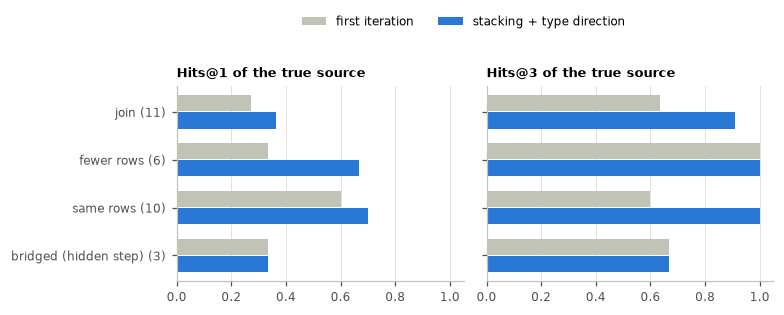

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.3), sharey=True, gridspec_kw={"wspace": 0.08})
y = np.arange(len(OPERATIONS))
for ax, k in zip(axes, [1, 3]):
    ax.barh(y - 0.18, per_operation[f"Hits@{k}, first iteration"], height=0.34, color=LIGHT_GREY, label="first iteration")
    ax.barh(y + 0.18, per_operation[f"Hits@{k}, final"], height=0.34, color=BLUE, label="stacking + type direction")
    ax.set_xlim(0, 1.05)
    ax.set_title(f"Hits@{k} of the true source")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, [f"{o} ({n})" for o, n in zip(OPERATIONS, per_operation.links)])
axes[0].invert_yaxis()
axes[0].legend(loc="upper center", ncol=2, bbox_to_anchor=(1.0, 1.42))
fig.tight_layout()
fig.savefig(FIGURES / "it2_03_scenarios.png")
plt.show()

* **Joins** are the hardest case for the first iteration (Hits@1 0.27): a lookup table such as `Shippers` or
  `Customers` gives one column to a five-column view, so `mean` dilutes its evidence. The final system puts the true
  source into the top 3 for 10 of 11 join links, mostly because the reverse pairs (the view's own derived tables)
  are demoted.
* **Fewer rows** (selection, aggregation) and **same rows** (copies) reach Hits@3 = 1.0 in the final system.
* **Bridged** links stay hard: the final table is a transformation of a temporary table that is not in the export.
  One of them (`TableInventoryStaging -> FinalProcurementAudit`) even drops from rank 1 to rank 10 with stacking,
  whose weights were learned mostly on direct links.
* This mirrors the paper, where join tasks are also the weakest (Hits@10 0.57-0.68 for RDDL vs 0.66-0.74 for the
  selection and union tasks).

## 6. Summary: from the first to the second iteration

In [14]:
progress = {
    "first iteration (Jaccard distance + mean)": first,
    "hybrid mean/max aggregation": hybrid_aggregation(scored["raw"], "Jaccard distance",
                                                               fit_weight(scored["raw"], "Jaccard distance")[0]),
    "average of 6 matchers": systems["average: all six matchers (mean)"],
    "stacking (logistic regression)": stacked,
    "stacking + catalog direction": apply_direction(stacked, direction_signals(pairs, stacked, splits, CATALOG_ORDER),
                                                    ("vote_type",)),
    "stacking + type direction (final)": final,
}
summary = pd.DataFrame({name: held(s) for name, s in progress.items()}).T[METRICS]
summary.round(3)

,PR-AUC,AUROC,Hits@1,Hits@3,MRR
first iteration (Jaccard distance + mean),0.206,0.860,0.4,0.733,0.589
hybrid mean/max aggregation,0.199,0.842,0.4,0.733,0.600
average of 6 matchers,0.215,0.845,0.4,0.867,0.644
stacking (logistic regression),0.255,0.860,0.4,0.933,0.651
stacking + catalog direction,0.257,0.874,0.4,0.933,0.651
stacking + type direction (final),0.358,0.924,0.6,0.933,0.762


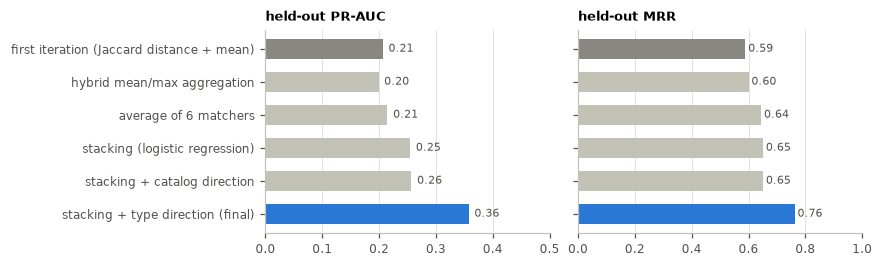

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.4), sharey=True, gridspec_kw={"wspace": 0.1})
order = list(summary.index)[::-1]
colors = [BLUE if "final" in n else GREY if "first" in n else LIGHT_GREY for n in order]
for ax, metric in zip(axes, ["PR-AUC", "MRR"]):
    values = summary.loc[order, metric]
    ax.barh(range(len(order)), values, color=colors, height=0.6)
    for yy, v in enumerate(values):
        ax.text(v + 0.01, yy, f"{v:.2f}", va="center", fontsize=7, color=MUTED)
    ax.set_xlim(0, max(0.5, values.max() * 1.25) if metric == "PR-AUC" else 1.0)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"held-out {metric}")
axes[0].set_yticks(range(len(order)), order)
fig.tight_layout()
fig.savefig(FIGURES / "it2_02_progress.png")
plt.show()

For the comparison with the reference paper (first iteration, section 7) we repeat the paper-style Hits@10: each true
link is ranked against random samples of 50 or 100 negative pairs of its split.

In [16]:
paper_style = pd.DataFrame({name: {f"Hits@10 vs {n} negatives": hits_vs_sampled_negatives(s[s.split.isin(HELD_OUT)], n)
                                   for n in (50, 100)}
                            for name, s in [("first iteration", first), ("final", final)]}).T
paper_style.round(2)

,Hits@10 vs 50 negatives,Hits@10 vs 100 negatives
first iteration,0.74,0.53
final,0.88,0.75


In [17]:
t = best_threshold(final[final.split == "train"])
related = {"lineage", "reverse", "indirect"}
rows = {}
for view, members in [("train", ["train"]), ("held-out", HELD_OUT)]:
    part = final[final.split.isin(members)]
    rows[view] = {**threshold_metrics(part, t),
                  "same lineage chain": part[part.score >= t].label.isin(related).mean()}
pd.DataFrame(rows).T.round(3)

,threshold,predicted links,Precision,Recall,F1,same lineage chain
train,0.833,10.0,0.500,0.455,0.476,0.500
held-out,0.833,29.0,0.345,0.526,0.417,0.655


At a threshold chosen on train, the final system finds about half of the held-out links (recall 0.53 vs 0.32 in the
first iteration) at a slightly higher precision (0.34 vs 0.27). The price: in the first iteration every predicted
pair was inside a true lineage chain, now about two thirds are (true links included). Because stacking gives weight to `max`-type
scores, pairs that share an `OrderID` column but belong to different chains (e.g. `TableFulfillmentLeads ->
OrderSummary`) pass the threshold. For a *set* of links the threshold system still needs work; as a *ranking* the
final system is clearly better.

## 7. Main outcomes

In [18]:
fh, sh = held(first), held(final)
outcomes = {
    "table names on/off": "no effect on COMA, Cupid, Jaccard; < 0.01 PR-AUC for SF and Distribution-based",
    "hybrid mean/max aggregation": f"no gain (held-out PR-AUC {hybrid_rows[0]['held-out PR-AUC, hybrid']:.2f} vs {fh['PR-AUC']:.2f})",
    "stacking, C chosen by CV on train": f"C = {C}; PR-AUC {fh['PR-AUC']:.2f} -> {held(stacked)['PR-AUC']:.2f}, Hits@3 {fh['Hits@3']:.2f} -> {held(stacked)['Hits@3']:.2f}",
    "direction correct: score / type order": f"{direction_table.loc['score only (first iteration)', 'correct']}/30 -> {direction_table.loc['type only', 'correct']}/30",
    "final held-out PR-AUC / AUROC": f"{sh['PR-AUC']:.2f} / {sh['AUROC']:.2f} (first iteration {fh['PR-AUC']:.2f} / {fh['AUROC']:.2f})",
    "final held-out Hits@1 / Hits@3 / MRR": f"{sh['Hits@1']:.2f} / {sh['Hits@3']:.2f} / {sh['MRR']:.2f}",
    "final precision / recall at train threshold (held-out)": f"{rows['held-out']['Precision']:.2f} / {rows['held-out']['Recall']:.2f}",
    "paper-style Hits@10 vs 50 / 100 negatives": f"{paper_style.loc['final'].iloc[0]:.2f} / {paper_style.loc['final'].iloc[1]:.2f} (first iteration {paper_style.loc['first iteration'].iloc[0]:.2f} / {paper_style.loc['first iteration'].iloc[1]:.2f})",
    "hardest scenario": "joins (single-column sources) and bridged links",
}
summary.to_csv(RESULTS_DIR / "metrics_second_iteration.csv")
pd.Series(outcomes, name="value").to_frame()

,value
table names on/off,"no effect on COMA, Cupid, Jaccard; < 0.01 PR-AUC for SF ..."
hybrid mean/max aggregation,no gain (held-out PR-AUC 0.20 vs 0.21)
"stacking, C chosen by CV on train","C = 0.1; PR-AUC 0.21 -> 0.25, Hits@3 0.73 -> 0.93"
direction correct: score / type order,18/30 -> 29/30
final held-out PR-AUC / AUROC,0.36 / 0.92 (first iteration 0.21 / 0.86)
final held-out Hits@1 / Hits@3 / MRR,0.60 / 0.93 / 0.76
final precision / recall at train threshold (held-out),0.34 / 0.53
paper-style Hits@10 vs 50 / 100 negatives,0.88 / 0.75 (first iteration 0.74 / 0.53)
hardest scenario,joins (single-column sources) and bridged links


**Open points (see `plan.md`)**

1. The type-order direction relies on the benchmark's naming convention; test it with catalog information only
   (creation time) or on the paper's full benchmark (SQL Server scripts).
2. Stacking is fitted on 11 positive pairs; a cross-split evaluation (train on multi, test on train) would show how
   stable the weights are.
3. Bridged links need the temporary tables, i.e. lineage of intermediate objects that are dropped.
4. Optional: write the predicted links as `tableDerivedFrom` triples into the RDDL knowledge graph (rdflib).